# 01 · Dữ liệu và ground truth — TV5
Mask SOS là nhãn tham chiếu semantic, không phải xác nhận hiện trường. Không có metadata góc tới, gió hay mã cảnh.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sar_oil import core, reference
from sar_oil.data import records, read_pair, MANIFEST
from sar_oil.experiments import OUT
def table(rows, columns):
    def value(x): return (f'{x:.3e}' if 0<abs(x)<1e-4 else f'{x:.6f}') if isinstance(x,float) else str(x)
    display(HTML('<table><tr>'+''.join('<th>'+c+'</th>' for c in columns)+'</tr>'+''.join('<tr>'+''.join('<td>'+value(r.get(c,''))+'</td>' for c in columns)+'</tr>' for r in rows)+'</table>'))
def load(name):
    p=OUT/name
    if not p.exists(): raise FileNotFoundError(f'Missing {p}. Run python scripts/sos.py reproduce first.')
    return json.loads(p.read_text(encoding='utf-8'))


In [2]:
from collections import Counter
manifest=json.loads(MANIFEST.read_text())
table([dict(split=k,images=v) for k,v in Counter(r['split'] for r in manifest['records']).items()],['split','images'])
assert len(records('train'))==2683 and len(records('validation'))==671 and len(records('test'))==839
assert not (set(r['image_sha256'] for r in records('train')) & set(r['image_sha256'] for r in records('test')))
print('seed:',manifest['seed'],'mask threshold:',manifest['mask_threshold'])

split,images
external_train,3101
train,2683
validation,671
external_val,776
test,839


seed: 2026 mask threshold: 128


Chia theo patch, phân tầng mask rỗng; chưa chứng minh độc lập theo cảnh. 853 mask train Sentinel có giá trị trung gian. Mặc định >=128; 64/192 chỉ khảo sát độ nhạy nhãn.

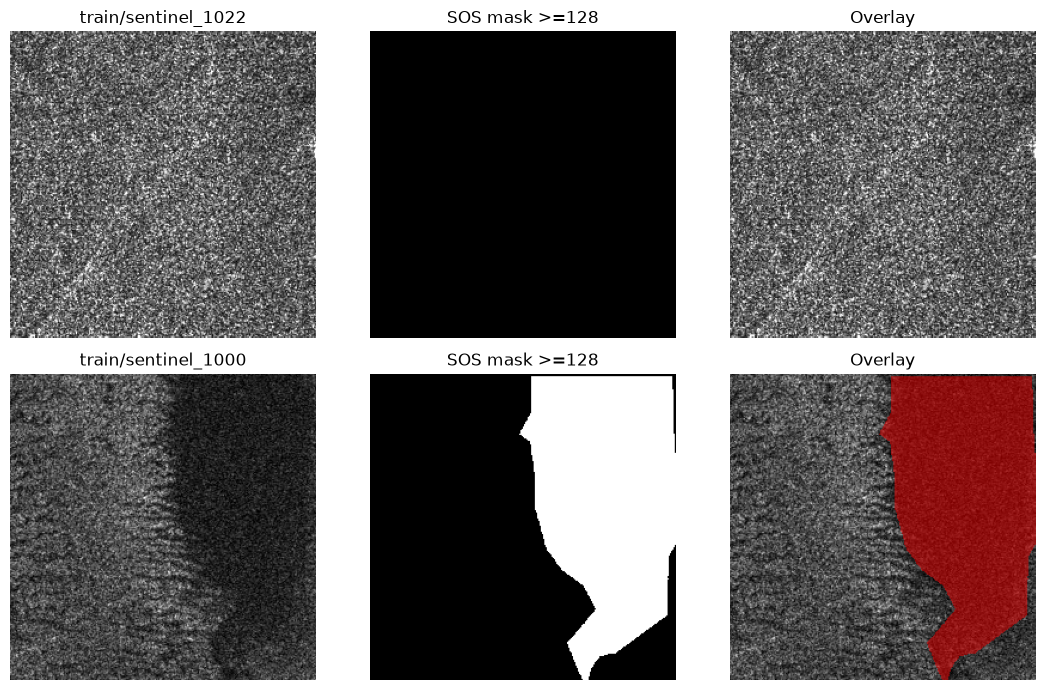

In [3]:
rows=records('validation')
examples=[next(r for r in rows if r['empty']),next(r for r in rows if not r['empty'])]
fig,axes=plt.subplots(2,3,figsize=(11,7))
for i,r in enumerate(examples):
    a,g=read_pair(r); axes[i,0].imshow(a,cmap='gray'); axes[i,0].set_title(r['id'])
    axes[i,1].imshow(g,cmap='gray',vmin=0,vmax=1); axes[i,1].set_title('SOS mask >=128')
    axes[i,2].imshow(a,cmap='gray'); axes[i,2].imshow(np.ma.masked_where(~g,g),alpha=.5,cmap='autumn'); axes[i,2].set_title('Overlay')
for ax in axes.flat: ax.axis('off')
plt.tight_layout(); plt.show()